In [110]:
import numpy as np

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, IterableDataset, DataLoader

import torchmetrics

from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE

import pandas as pd

from nltk.tokenize import WordPunctTokenizer
from collections import Counter

from tqdm.auto import tqdm, trange

import matplotlib.pyplot as plt
from IPython.display import clear_output

import print_color

In [10]:
MIN_SENTENCE_LEN = 20
MIN_WORD_COUNT = 10

In [11]:
data_path = '../week02_lm/arxivData.json'

In [12]:
tokenizer = WordPunctTokenizer()

In [13]:
data = pd.read_json(data_path)
texts = data['summary'].str.lower()
texts = texts.apply(tokenizer.tokenize)
texts = texts.apply(lambda array: [tok for tok in array if tok.isalpha()]).tolist()
texts = list(filter(lambda text: len(text) >= MIN_SENTENCE_LEN, texts))

In [14]:
train_texts, val_texts = train_test_split(texts, test_size = 0.1)

In [15]:
counter = Counter()
for text in train_texts:
    counter.update(text)

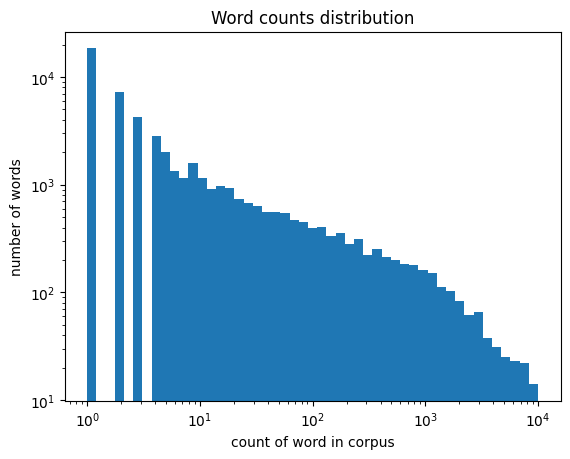

In [16]:
plt.hist(counter.values(), range = (0,10000), bins = np.logspace(0, 4, 50))
plt.title('Word counts distribution')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('count of word in corpus')
plt.ylabel('number of words')
plt.show()

In [17]:
vocab = list(filter(lambda token: counter[token] > MIN_WORD_COUNT, counter))
UNK_INDEX = -100

tok_to_idx = {token:i for i, token in enumerate(vocab)}
idx_to_tok = {i:token for token, i in tok_to_idx.items()}

idx_array_train = []
idx_array_val = []

for text in tqdm(train_texts):
    idx_array_train.append([tok_to_idx[tok] for tok in text if tok in vocab])

for text in tqdm(val_texts):
    idx_array_val.append([tok_to_idx[tok] for tok in text if tok in vocab])

  0%|          | 0/36833 [00:00<?, ?it/s]

  0%|          | 0/4093 [00:00<?, ?it/s]

In [18]:
def normalize_counter(counter):

    total = counter.total()
    
    for word in counter:
        counter[word] = counter[word]/total

def get_word_distribution(word_counter, vocab):

    frequencies = Counter()
    for word in vocab:
        frequencies[word] = word_counter[word]
    
    normalize_counter(frequencies)

    return frequencies

def flatten_distribution(frequencies, power):

    result = Counter()
    
    for word in frequencies:
        result[word] = frequencies[word] ** power
    
        normalize_counter(result)

    return result


In [19]:
freq_power = 0.75
frequencies = get_word_distribution(counter, vocab)
neg_sampling_freqs = flatten_distribution(frequencies, freq_power)

neg_sampling_freqs_from_idx = np.zeros(len(neg_sampling_freqs), dtype = 'float')
for token, prob in neg_sampling_freqs.items():
    neg_sampling_freqs_from_idx[tok_to_idx[token]] = prob

In [20]:
def keep_prob(freq, t):

    return np.minimum(1.0, (t / (freq + 1e-12)) ** 0.5 + t / (freq + 1e-12))

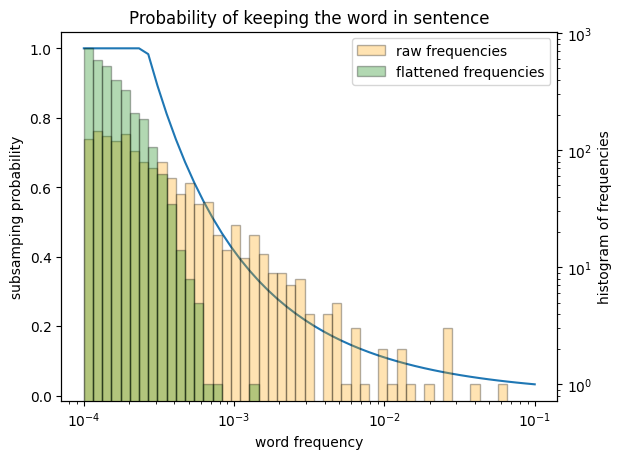

In [21]:
xx = np.logspace(-4,-1, 50)
t = 1e-4

plt.plot(xx,keep_prob(xx, t))
plt.xscale('log')
plt.title('Probability of keeping the word in sentence')
plt.ylabel('subsamping probability')
plt.xlabel('word frequency')

twin_ax = plt.gca().twinx()

twin_ax.hist(frequencies.values(), bins = xx, density = False, color = 'orange', 
             edgecolor = 'black', alpha = 0.3, label = 'raw frequencies')
twin_ax.hist(neg_sampling_freqs.values(), bins = xx, density = False, color = 'green', 
             edgecolor = 'black', alpha = 0.3, label = 'flattened frequencies')

twin_ax.set_yscale('log')
twin_ax.set_ylabel('histogram of frequencies')
twin_ax.legend()

plt.show()

In [70]:
class Word2VecDataset(IterableDataset):
    
    def __init__(self, 
                 idx_array, 
                 freq_dict,
                 tok_to_idx,
                 subsample_thr = 1e-4,
                 context_radius = 5,
                 train = False,
                 buffer_size = 2000,
                ):

        self.idx_array = idx_array
        self.freq_table = np.zeros(len(tok_to_idx), dtype = 'float')
        for token, prob in freq_dict.items():
            self.freq_table[tok_to_idx[token]] = prob
        
        self.subsample_thr = subsample_thr
        self.context_radius = context_radius
        self.train = train

        array_lengths = [len(line) - 2*context_radius for line in idx_array]
        self.length = sum(array_lengths) // 2

        self.buffer_size = buffer_size

    def iter_with_buffer(self, source):

        buffer = []

        for item in source:
            if len(buffer) < self.buffer_size:
                buffer.append(item)
                continue

            idx = np.random.randint(self.buffer_size)
            yield buffer[idx]
            buffer[idx] = item

        np.random.shuffle(buffer)
        yield from buffer        

    def subsample(self, tokens: np.ndarray):

        sample = np.random.random_sample(len(tokens))
        freqs = self.freq_table[tokens]
        keep = sample < keep_prob(freqs, self.subsample_thr)
        return tokens[keep]

    def __len__(self):

        """
        approximate length (when no subsampling is performed)
        actual length is less than that and is stochastic
        """

        return self.length

    def iterate_over_line(self, line_idx: int):

        line = np.array(self.idx_array[line_idx])
        if self.train:
            line = self.subsample(line)
            
        central_indices = np.arange(len(line) - 2*self.context_radius)
        central_indices += self.context_radius
        
        if self.train:
            np.random.shuffle(central_indices)

        for central_idx in central_indices:
            context = line[central_idx-self.context_radius:central_idx+self.context_radius+1].tolist()
            central_word = context.pop(self.context_radius)

            yield central_word, np.array(context)
        
    def generate_examples(self):

        if self.train:
            line_indices = np.random.permutation(len(self.idx_array))
        else:
            line_indices = np.arange(len(self.idx_array))
        
        for line_idx in line_indices:
            yield from self.iterate_over_line(line_idx)

    def __iter__(self):

        iterable = self.generate_examples()
        
        if self.train:
            iterable = self.iter_with_buffer(iterable)
        
        yield from iterable
            

In [71]:
train_ds = Word2VecDataset(idx_array_train, 
                           freq_dict=frequencies, 
                           tok_to_idx=tok_to_idx,
                           context_radius=5, 
                           train = True)

val_ds = Word2VecDataset(idx_array_val, 
                         freq_dict=frequencies, 
                         tok_to_idx=tok_to_idx,
                         context_radius=5, 
                         train = False)

In [72]:
bs = 256

train_dl = DataLoader(train_ds, batch_size=bs)
val_dl = DataLoader(val_ds, batch_size=bs)

In [73]:
for batch in train_dl:
    break

In [74]:
def print_word_in_context(batch, idx_to_tok, max_rows = 10):
    word_batch, context_batch = batch
    
    for i, (w, c) in enumerate(zip(word_batch, context_batch)):

        if i > max_rows:
            break

        w,c = w.item(), c.numpy()
        print_color.print(*[idx_to_tok[x] for x in c[:len(c)//2]], color = 'yellow', end = ' ')
        print_color.print(idx_to_tok[w], color = 'magenta', end = ' ')
        print_color.print(*[idx_to_tok[x] for x in c[len(c)//2:]], color = 'yellow')

In [75]:
print_word_in_context(batch, idx_to_tok)

expressiveness four analytic distances assessed respect variation distances used deriving new
is scheduled perform route in period planning horizon at period is
interfaces architecture contrasts monolithic nature many implementations experimental indicate software engineering
characteristic most the motions sphere uniform derive relationship motion vectors various
us to obtain constant memory consumption per sub at same retaining
extracted from hyperspectral gb involve penalties rows columns obtain significant speed
correlated data correlation makes training network hard especially rnn overcome issue
special cases hash embedding hash embeddings considered extension improvement over existing
secondly i evaluate practice compositional methodology explicitly deals levels lexical ambiguity
explore effect modularity degree distribution evolutionary experiments i confirm finding modularity
identities few samples variability generated speech priming buffer generating audio experimental


In [134]:
class SkipGram(nn.Module):

    def __init__(self, vocab_size, dim = 300):
        
        super().__init__()
        self.vocab_size = vocab_size
        self.word_emb = nn.Embedding(num_embeddings=vocab_size, embedding_dim=dim)
        self.context_emb = nn.Embedding(num_embeddings=vocab_size, embedding_dim=dim)

    def forward(self, word_batch, context_batch):

        """
        word_batch: tensor [bs]
        context_batch: tensor [bs, context_size, n_samples]
        """

        word_emb = self.word_emb(word_batch) # [bs, emb_dim]
        context_emb = self.context_emb(context_batch) #[bs, context_size, n_samples, emb_dim]

        logits = torch.einsum('bijk,bk->bij',context_emb, word_emb)  #[bs, context_size, n_samples]
        return logits

    @torch.inference_mode()
    def predict(self, word_batch):

        word_emb = self.word_emb(word_batch) # [bs, emb_dim]
        context_emb = self.context_emb.weight # [vocab_size, emb_dim]

        logits = word_emb @ context_emb.T # [bs, vocab_size]
        return logits

    @torch.inference_mode()
    def generate_context(self, word, topk = 5):
        logits = self.predict(word.unsqueeze(0)).squeeze(0)
        return torch.topk(logits,k = topk).indices

    @torch.inference_mode()
    def get_closest(self, word, topk = 5):
        vector = self.word_emb(word)
        vector = F.normalize(vector, dim = 0)
        similarities = vector @ F.normalize(self.word_emb.weight).T
        return torch.topk(similarities,k = topk+1).indices[1:]
                
    @torch.inference_mode()
    def get_vectors(self):
        vectors =  self.word_emb.weight.clone()
        return vectors

class CBoW(nn.Module):

    def __init__(self, vocab_size, dim = 300):
        
        super().__init__()
        self.vocab_size = vocab_size
        self.context_emb = nn.EmbeddingBag(num_embeddings=vocab_size, embedding_dim=dim, mode = 'mean')
        self.word_emb = nn.Embedding(num_embeddings=vocab_size, embedding_dim=dim)

    def forward(self, word_batch, context_batch):

        """
        word_batch: tensor [bs, n_samples]
        context_batch: tensor [bs, context_size]
        """

        word_emb = self.word_emb(word_batch) # [bs, n_samples, emb_dim]
        context_emb = self.context_emb(context_batch) #[bs, emb_dim]

        logits = torch.einsum('bk,bik->bi',context_emb, word_emb)  #[bs, n_samples]
        return logits

    @torch.inference_mode()
    def predict(self, context_batch):

        context_emb = self.context_emb(context_batch) #[bs, emb_dim]
        word_emb = self.word_emb.weight # [vocab_size, emb_dim]

        logits = context_emb @ word_emb.T # [bs, vocab_size]
        return logits

    @torch.inference_mode()
    def generate_word(self, context, topk = 5):
        logits = self.predict(context.unsqueeze(0)).squeeze(0)
        return torch.topk(logits,k = topk).indices

    @torch.inference_mode()
    def get_closest(self, word, topk = 5):
        vector = self.word_emb(word)
        vector = F.normalize(vector, dim = 0)
        similarities = vector @ F.normalize(self.word_emb.weight).T
        return torch.topk(similarities,k = topk+1).indices[1:]
                
    @torch.inference_mode()
    def get_vectors(self):
        vectors =  self.word_emb.weight.clone()
        return vectors

In [125]:
skip_gram_model = SkipGram(vocab_size=len(vocab))

In [159]:
cbow_model = CBoW(vocab_size=len(vocab))

In [78]:
N_NEG_SAMPLES = 20

In [165]:
def skip_gram_train_step(model, word_batch, context_batch, sampling_probs, n_neg_samples):


    bs, context_length = context_batch.shape
    vocab_size = model.vocab_size
    
    pos_logits = model(word_batch, context_batch.unsqueeze(-1)) #[bs, context_size, 1]
    
    neg_indices = np.random.choice(vocab_size, 
                                   size = (bs, context_length, n_neg_samples), 
                                   p = sampling_probs)

    neg_indices = torch.tensor(neg_indices, device = word_batch.device) #[bs, context_size, n_samples]
    neg_logits = model(word_batch, neg_indices) #[bs, context_size, n_samples]

    logits = torch.cat([pos_logits, neg_logits], dim = -1)  #[bs, context_size, n_samples+1]
    
    targets = torch.cat([torch.tensor([1], dtype = torch.int),torch.zeros(n_neg_samples, dtype = torch.int)]) # n_samples+1
    targets = targets.expand(1,1,-1).repeat(bs, context_length, 1) #[bs, context_size, n_samples+1]
    
    loss = F.binary_cross_entropy_with_logits(logits, targets.to(torch.float), reduction = 'none')
    loss = loss.sum(-1).mean()

    return loss

def intersection_size(x,y):

    x,y = x.numpy(), y.numpy()
    result = []
    for x_arr, y_arr in zip(x,y):
        result.append(np.intersect1d(x_arr, y_arr).shape[0])
        
    return np.array(result)

def skip_gram_val_step(model, word_batch, context_batch):

    logits = model.predict(word_batch)
    pred_indices = torch.topk(logits,k = context_batch.shape[1]).indices

    recall = intersection_size(pred_indices, context_batch).mean()
    return recall

In [173]:
def cbow_train_step(model, word_batch, context_batch, sampling_probs, n_neg_samples):

    bs, context_length = context_batch.shape
    vocab_size = model.vocab_size
    
    pos_logits = model(word_batch.unsqueeze(-1), context_batch) #[bs, 1]
    
    neg_indices = np.random.choice(vocab_size, 
                                   size = (bs, n_neg_samples), 
                                   p = sampling_probs)

    neg_indices = torch.tensor(neg_indices, device = word_batch.device) #[bs, n_samples]
    neg_logits = model(neg_indices, context_batch) #[bs, n_samples]

    logits = torch.cat([pos_logits, neg_logits], dim = -1)  #[bs, n_samples+1]
    
    targets = torch.cat([torch.tensor([1], dtype = torch.int),torch.zeros(n_neg_samples, dtype = torch.int)]) # n_samples+1
    targets = targets.expand(1,-1).repeat(bs, 1) #[bs, n_samples+1]
    
    loss = F.binary_cross_entropy_with_logits(logits, targets.to(torch.float), reduction = 'none')
    loss = loss.sum(-1).mean()

    return loss

def cbow_val_step(model, word_batch, context_batch):

    logits = model.predict(context_batch)
    pred_indices = torch.topk(logits,k = 5).indices

    top5_accuracy = (pred_indices == word_batch.view(-1,1)).any(dim = 1)
    return top5_accuracy.to(torch.float).mean()

In [174]:
def train_epoch(model, 
                dataloader,
                optimizer,
                step_fn,
                sampling_probs,
                n_samples = N_NEG_SAMPLES,
                device = 'cpu',
                train_history = None):

    model.to(device)

    total = len(dataloader)

    for i, batch in enumerate(tqdm(dataloader, leave = False)):

        word_batch, context_batch = batch
        word_batch = word_batch.to(device)
        context_batch = context_batch.to(device) #[bs, context_size]

        bs, context_length = context_batch.shape
        cutoff = np.random.randint(0,context_length // 2)

        context_batch = context_batch[:,cutoff:context_length-cutoff]

        loss = step_fn(model, word_batch, context_batch, sampling_probs, n_samples)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_history.append(loss.item())

        if i % 50 == 0:
            
            clear_output()
            print(f"step {i} / {total}")
            plt.plot(train_history)
            plt.xlabel('step')
            plt.yscale('log')
            plt.ylabel('loss')
            plt.title('Training progress')
            plt.show()

@torch.inference_mode()
def val_epoch(model, dataloader, step_fn, device = 'cpu'):

    metrics = []

    model.to(device)
    for batch in tqdm(dataloader, leave = False):

        word_batch, context_batch = batch
        word_batch = word_batch.to(device)
        context_batch = context_batch.to(device)

        metric = step_fn(model, word_batch, context_batch)

        metrics.append(metric)

    return np.mean(metrics)

In [175]:
def train_loop(model, 
               n_epochs,
               train_dl, 
               val_dl, 
               optimizer, 
               sampling_probs, 
               train_step_fn, 
               val_step_fn, 
               device = 'cpu'):

    metrics = []
    train_history = []
    last_val_metric = None
    
    for epoch in range(n_epochs):
        print(f"{epoch=}, {last_val_metric = }")

        train_epoch(model, 
                train_dl,
                optimizer,
                train_step_fn,
                sampling_probs,
                device = device,
                train_history = train_history)

        metric = val_epoch(model, 
                           val_dl, 
                           val_step_fn, 
                           device)

        metrics.append(metric)
        last_val_metric = metric

    return metrics

In [86]:
optimizer = torch.optim.AdamW(skip_gram_model.parameters(), lr = 1e-3)

step 4550 / 10172


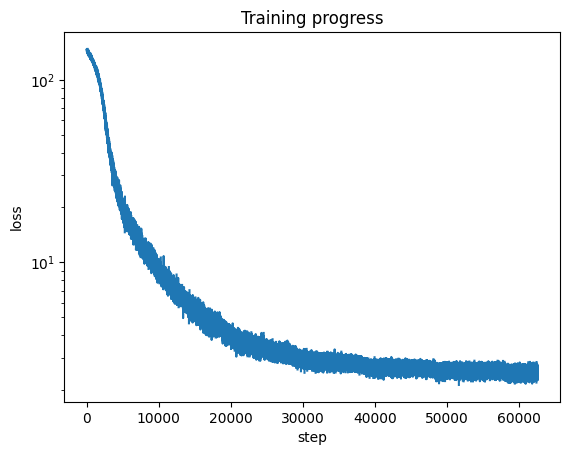

KeyboardInterrupt: 

In [87]:
n_epochs = 10
val_metrics = train_loop(skip_gram_model, 
           n_epochs,
           train_dl, 
           val_dl, 
           optimizer, 
           neg_sampling_freqs_from_idx, 
           skip_gram_train_step, 
           skip_gram_val_step)

In [171]:
optimizer = torch.optim.AdamW(cbow_model.parameters(), lr = 1e-3)

step 9650 / 10172


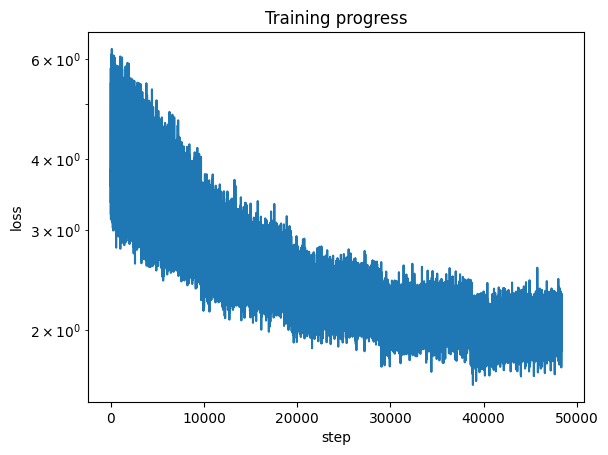

  0%|          | 0/1131 [00:00<?, ?it/s]

In [176]:
n_epochs = 5
val_metrics = train_loop(cbow_model, 
           n_epochs,
           train_dl, 
           val_dl, 
           optimizer, 
           neg_sampling_freqs_from_idx, 
           cbow_train_step, 
           cbow_val_step)

In [178]:
val_metrics

[np.float32(0.007601818),
 np.float32(0.01374286),
 np.float32(0.020706814),
 np.float32(0.026913479),
 np.float32(0.030300386)]

In [90]:
def get_closest(model, word, tok_to_idx, idx_to_tok, n_words = 5):

    closest = model.get_closest(torch.tensor(tok_to_idx[word]), topk = n_words)
    return [idx_to_tok[w.item()] for w in closest]

In [95]:
torch.save(skip_gram_model.state_dict(), 'skip_gram_model.pt')

In [179]:
torch.save(cbow_model.state_dict(), 'cbow_model.pt')

In [127]:
#skip_gram_model.load_state_dict(torch.load('skip_gram_model.pt'))

In [132]:
for word in ['deep', 'variational', 'accuracy', 'quantum', 'transformer', 'imitation']:

    print(word, '-->', get_closest(skip_gram_model, word, tok_to_idx, idx_to_tok))

deep --> ['convolutional', 'neural', 'networks', 'network', 'learning']
variational --> ['inference', 'bayesian', 'posterior', 'likelihood', 'stochastic']
accuracy --> ['performance', 'efficiency', 'quality', 'overall', 'precision']
quantum --> ['logical', 'classical', 'genetic', 'artificial', 'intelligence']
transformer --> ['convolutional', 'transformation', 'recurrent', 'rotation', 'learnt']
imitation --> ['demonstration', 'reinforcement', 'policy', 'equilibria', 'learning']


In [177]:
for word in ['deep', 'variational', 'accuracy', 'quantum', 'transformer', 'imitation']:

    print(word, '-->', get_closest(cbow_model, word, tok_to_idx, idx_to_tok))

deep --> ['convolutional', 'neural', 'networks', 'cnn', 'cnns']
variational --> ['vae', 'amortized', 'elbo', 'posterior', 'posteriors']
accuracy --> ['accuracies', 'performances', 'performance', 'efficiency', 'precision']
quantum --> ['physics', 'reservoir', 'evolutionary', 'circuits', 'entanglement']
transformer --> ['stacked', 'pyramid', 'skeleton', 'fps', 'ppi']
imitation --> ['resting', 'youtu', 'hrl', 'postulated', 'gail']


In [190]:
def generate_word_from_context(model, context, tok_to_idx, idx_to_tok, n_words = 5):

    word_index = model.generate_word(torch.tensor([tok_to_idx[c] for c in context]), topk = n_words)
    return [idx_to_tok[w.item()] for w in word_index]

def print_predicted_words_from_context(context, predicted):

    context_length = len(context)
    print_color.print(*context[:context_length//2], end = ' ', color = 'yellow')
    print_color.print('???', color = 'magenta', end = ' ')
    print_color.print(*context[context_length//2:], end = ' ', color = 'yellow')
    print('--->', end = ' ')
    print_color.print(*predicted, color = 'magenta', sep = '/')

In [198]:
phrases = ["we introduce new deep learning approach",
          "deep reinforcement for sequences",
          "on several translation tasks"]

In [199]:
for phrase in phrases:

    words = generate_word_from_context(cbow_model, phrase.split(), tok_to_idx, idx_to_tok)
    print_predicted_words_from_context(phrase.split(), words)

we introduce new ??? deep learning approach ---> novel/scalable/deep/new/fast
deep reinforcement ??? for sequences ---> deterministic/deep/reinforcement/learning/rl
on several ??? translation tasks ---> machine/translation/compare/promising/perform
